# Intro teórica

## Definición: Clasificador Bayesiano

Sean $k$ poblaciones, $x \in \mathbb{R}^p$ puede pertenecer a cualquiera $g \in \mathcal{G}$ de ellas. Bajo un esquema bayesiano, se define entonces $\pi_j \doteq P(G = j)$ la probabilidad *a priori* de que $X$ pertenezca a la clase *j*, y se **asume conocida** la distribución condicional de cada observable dado su clase $f_j \doteq f_{X|G=j}$.

De esta manera dicha probabilidad *a posteriori* resulta
$$
P(G|_{X=x} = j) = \frac{f_{X|G=j}(x) \cdot p_G(j)}{f_X(x)} \propto f_j(x) \cdot \pi_j
$$

La regla de decisión de Bayes es entonces
$$
H(x) \doteq \arg \max_{g \in \mathcal{G}} \{ P(G|_{X=x} = j) \} = \arg \max_{g \in \mathcal{G}} \{ f_j(x) \cdot \pi_j \}
$$

es decir, se predice a $x$ como perteneciente a la población $j$ cuya probabilidad a posteriori es máxima.

*Ojo, a no desesperar! $\pi_j$ no es otra cosa que una constante prefijada, y $f_j$ es, en su esencia, un campo escalar de $x$ a simplemente evaluar.*

## Distribución condicional

Para los clasificadores de discriminante cuadrático y lineal (QDA/LDA) se asume que $X|_{G=j} \sim \mathcal{N}_p(\mu_j, \Sigma_j)$, es decir, se asume que cada población sigue una distribución normal.

Por definición, se tiene entonces que para una clase $j$:
$$
f_j(x) = \frac{1}{(2 \pi)^\frac{p}{2} \cdot |\Sigma_j|^\frac{1}{2}} e^{- \frac{1}{2}(x-\mu_j)^T \Sigma_j^{-1} (x- \mu_j)}
$$

Aplicando logaritmo (que al ser una función estrictamente creciente no afecta el cálculo de máximos/mínimos), queda algo mucho más práctico de trabajar:

$$
\log{f_j(x)} = -\frac{1}{2}\log |\Sigma_j| - \frac{1}{2} (x-\mu_j)^T \Sigma_j^{-1} (x- \mu_j) + C
$$

Observar que en este caso $C=-\frac{p}{2} \log(2\pi)$, pero no se tiene en cuenta ya que al tener una constante aditiva en todas las clases, no afecta al cálculo del máximo.

## LDA

En el caso de LDA se hace una suposición extra, que es $X|_{G=j} \sim \mathcal{N}_p(\mu_j, \Sigma)$, es decir que las poblaciones no sólo siguen una distribución normal sino que son de igual matriz de covarianzas. Reemplazando arriba se obtiene entonces:

$$
\log{f_j(x)} =  -\frac{1}{2}\log |\Sigma| - \frac{1}{2} (x-\mu_j)^T \Sigma^{-1} (x- \mu_j) + C
$$

Ahora, como $-\frac{1}{2}\log |\Sigma|$ es común a todas las clases se puede incorporar a la constante aditiva y, distribuyendo y reagrupando términos sobre $(x-\mu_j)^T \Sigma^{-1} (x- \mu_j)$ se obtiene finalmente:

$$
\log{f_j(x)} =  \mu_j^T \Sigma^{-1} (x- \frac{1}{2} \mu_j) + C'
$$

## Entrenamiento/Ajuste

Obsérvese que para ambos modelos, ajustarlos a los datos implica estimar los parámetros $(\mu_j, \Sigma_j) \; \forall j = 1, \dots, k$ en el caso de QDA, y $(\mu_j, \Sigma)$ para LDA.

Estos parámetros se estiman por máxima verosimilitud, de manera que los estimadores resultan:

* $\hat{\mu}_j = \bar{x}_j$ el promedio de los $x$ de la clase *j*
* $\hat{\Sigma}_j = s^2_j$ la matriz de covarianzas estimada para cada clase *j*
* $\hat{\pi}_j = f_{R_j} = \frac{n_j}{n}$ la frecuencia relativa de la clase *j* en la muestra
* $\hat{\Sigma} = \frac{1}{n} \sum_{j=1}^k n_j \cdot s^2_j$ el promedio ponderado (por frecs. relativas) de las matrices de covarianzas de todas las clases. *Observar que se utiliza el estimador de MV y no el insesgado*

Es importante notar que si bien todos los $\mu, \Sigma$ deben ser estimados, la distribución *a priori* puede no inferirse de los datos sino asumirse previamente, utilizándose como entrada del modelo.

## Predicción

Para estos modelos, al igual que para cualquier clasificador Bayesiano del tipo antes visto, la estimación de la clase es por método *plug-in* sobre la regla de decisión $H(x)$, es decir devolver la clase que maximiza $\hat{f}_j(x) \cdot \hat{\pi}_j$, o lo que es lo mismo $\log\hat{f}_j(x) + \log\hat{\pi}_j$.

**Qué es este notebook.** Resuelve la consigna completa (ejercicios 1 a 14) con foco en tres cosas:
1. **Justificar con teoría** cada optimización (álgebra, complejidad, estabilidad numérica).
2. **Verificar** con pruebas que todas las variantes predicen *exactamente* lo mismo (contra un oráculo independiente).
   Las mismas pruebas están en `tests/test_qda.py` para correrlas sin abrir el notebook.
3. **Medir** tiempo y memoria con experimentos que barren $n$, $p$ y $k$, y comparar contra la teoría.

**Mapa del notebook**

| Sección | Contenido | Ejercicios |
|---|---|---|
| 0 | Configuración y convenciones | — |
| 1 | Teoría de QDA y preguntas del código base | Q3–Q7 |
| 2 | Tensorización (`TensorizedQDA`) | 1, 2 |
| 3 | Evitar la matriz $n \times n$ (`FasterQDA`, `EfficientQDA`) | 3, 4, 5, 6, 7 |
| 4 | Cholesky (`QDA_Chol1/2/3`) | 8, 9, 10, 11 |
| 5 | Cholesky tensorizado (`TensorizedChol`, `EfficientChol`) | 12, 13 |
| 6 | Pruebas de corrección y robustez numérica (versión ejecutable en `tests/`) | verificación |
| 7 | Comparación final de las 9 variantes | 14 |
| 8 | Conclusiones | — |

> **Idea rectora:** una optimización es válida si (a) es *matemáticamente equivalente*, (b) *se verifica* que lo es,
> y (c) se *mide* que mejora algo (tiempo, memoria o estabilidad) con la teoría prediciendo cuánto.

## 0. Configuración

In [28]:
import time
import tracemalloc
import warnings
from functools import lru_cache

import numpy as np
import numpy.linalg as LA
import pandas as pd
import seaborn as sns
from scipy import stats
from threadpoolctl import threadpool_limits   # viene con scikit-learn

from base.qda import QDA, TensorizedQDA, FasterQDA, EfficientQDA
from base.cholesky import QDA_Chol1, QDA_Chol2, QDA_Chol3, TensorizedChol, EfficientChol
from utils.bench import Benchmark
from utils.verification import (dataset_alta_dimension, prediccion_oraculo,
                                verificar_identidades_cholesky, verificar_truco_diagonal)
from utils.datasets import (get_iris_dataset, get_letters_dataset, get_penguins_dataset,
                            get_wine_dataset, label_encode, split_transpose)

# ---- Parámetros globales: todo lo ajustable vive acá ----
SEED = 6553                 # misma semilla que utils.bench, para resultados reproducibles
N_RUNS, WARMUP, MEM_RUNS = 200, 20, 20     # repeticiones del Benchmark (la consigna usa 1000/100/100)
USAR_LETTERS = True         # el dataset 'letters' (20.000 x 16, 26 clases) requiere descarga de OpenML
TEST_SZ_LETTERS = 0.05      # FasterQDA aloca k·n² doubles: con n=6.000 y k=26 serían ~7 GiB (ver sección 3)

sns.set_theme(style='whitegrid', context='notebook', palette='deep', rc={'figure.figsize': (8, 4.5)})

# El orden importa: es el orden en que aparecen en todas las tablas y gráficos.
MODELOS = {
    'QDA': QDA, 'TensorizedQDA': TensorizedQDA, 'FasterQDA': FasterQDA, 'EfficientQDA': EfficientQDA,
    'QDA_Chol1': QDA_Chol1, 'QDA_Chol2': QDA_Chol2, 'QDA_Chol3': QDA_Chol3,
    'TensorizedChol': TensorizedChol, 'EfficientChol': EfficientChol,
}
FAMILIA = {nombre: ('Cholesky' if 'Chol' in nombre else 'Inversa directa') for nombre in MODELOS}

### Convenciones de forma (shapes)
El código base trabaja con las observaciones en **columnas**, por eso `split_transpose` transpone todo.

| Símbolo | Significado | Shape |
|---|---|---|
| $X$ | observaciones | $(p, n)$ — cada **columna** es una observación |
| $y$ | etiquetas | $(1, n)$ — vector fila |
| $\mu_k$ | media de la clase $k$ | $(p, 1)$ |
| $\Sigma_k$ | covarianza de la clase $k$ | $(p, p)$ |

Tener estas formas presentes es *la* herramienta para no perderse: casi todo el TP consiste en
agregar un eje de clases $k$ y dejar que `@` y el broadcasting hagan el trabajo.

In [29]:
@lru_cache(maxsize=None)
def _datos(nombre: str):
    """Descarga/lee cada dataset una sola vez (penguins y letters vienen de OpenML)."""
    cargadores = {'iris': get_iris_dataset, 'wine': get_wine_dataset,
                  'penguins': get_penguins_dataset, 'letters': get_letters_dataset}
    X, y = cargadores[nombre]()
    return X, label_encode(y)


def cargar(nombre: str, test_size: float = 0.3, seed: int = SEED):
    """Devuelve (X_train, X_test, y_train, y_test) con observaciones en columnas."""
    X, y_codificado = _datos(nombre)
    return split_transpose(X, y_codificado, test_size=test_size, random_state=seed)


def ajustar(clase_modelo, X_train, y_train):
    """Instancia y entrena un modelo; devuelve el modelo ajustado."""
    modelo = clase_modelo()
    modelo.fit(X_train, y_train)
    return modelo


X_train, X_test, y_train, y_test = cargar('wine')
p, n_train = X_train.shape
n_test = X_test.shape[1]
k = len(np.unique(y_train))
print(f'Wine: p={p} features, k={k} clases, {n_train} obs. de train, {n_test} obs. de test')

Wine: p=13 features, k=3 clases, 124 obs. de train, 54 obs. de test


## 1. Teoría de QDA y las preguntas del código base

### 1.1 El modelo
QDA asume que, dada la clase $k$, las observaciones son gaussianas con **covarianza propia** $\Sigma_k$:
$x \mid G=k \sim \mathcal{N}(\mu_k, \Sigma_k)$. Por Bayes, la clase predicha maximiza la log-posterior
(las constantes comunes a todas las clases se descartan):

$$\delta_k(x) = \underbrace{\ln \pi_k}_{\text{a priori}} \; \underbrace{-\tfrac12 \ln|\Sigma_k|}_{\text{determinante}} \; \underbrace{-\tfrac12 (x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k)}_{\text{forma cuadrática}}, \qquad \hat{y} = \arg\max_k \delta_k(x)$$

El **costo** está en el último término: requiere $\Sigma_k^{-1}$ y un producto matricial por cada par (observación, clase).
Todo el TP es una secuencia de formas de calcular lo mismo más barato.

### 1.2 Preguntas dejadas como comentarios en el código base

In [30]:
# Q3 ─ ¿Para qué sirve np.bincount?  Cuenta cuántas veces aparece cada entero 0..k-1.
etiquetas = y_train.flatten().astype(int)
conteos = np.bincount(etiquetas)
print('Q3  bincount =', conteos, '→ a priori =', (conteos / etiquetas.size).round(3))
print('    Exige etiquetas enteras 0..k-1 (por eso label_encode) y el índice ES la clase.\n')

# Q4 ─ ¿Por qué _fit_params va al final de fit?  Usa len(self.log_a_priori) como cantidad de clases.
print("Q4  _fit_params itera `range(len(self.log_a_priori))`: necesita que el a priori ya exista.\n")

# Q5 ─ ¿Por qué hace falta el flatten?  y tiene shape (1, n), la máscara booleana también.
mascara_2d = (y_train == 0)
print('Q5  y == 0 tiene shape', mascara_2d.shape, '→ X[:, mascara] ', end='')
try:
    X_train[:, mascara_2d]
    print('funcionó')
except IndexError as error:
    print('falla:', str(error)[:70])
print('    con flatten() la máscara es 1-D (n,) y selecciona columnas:',
      X_train[:, mascara_2d.flatten()].shape, '\n')

# Q6 ─ ¿Por qué bias=True?  np.cov divide por n-1 (insesgado) o por n (máxima verosimilitud).
Xc = X_train[:, y_train.flatten() == 0]
print('Q6  n_clase =', Xc.shape[1], '| traza con n-1:', np.trace(np.cov(Xc)).round(4),
      '| traza con n (bias=True):', np.trace(np.cov(Xc, bias=True)).round(4))
print('    QDA se deriva del estimador de máxima verosimilitud de Σ (divide por n). La diferencia es un factor',
      f'n/(n-1) = {Xc.shape[1] / (Xc.shape[1] - 1):.3f}: relevante con clases chicas, despreciable con n grande.\n')

# Q7 ─ ¿Qué hace axis=1 y por qué no axis=0?  Las observaciones son columnas.
media = Xc.mean(axis=1, keepdims=True)
print('Q7  mean(axis=1, keepdims=True) →', media.shape, '(p,1): promedia sobre observaciones y queda lista para broadcasting;',
      'axis=0 promediaría features de cada observación:', Xc.mean(axis=0).shape)

Q3  bincount = [39 51 34] → a priori = [0.315 0.411 0.274]
    Exige etiquetas enteras 0..k-1 (por eso label_encode) y el índice ES la clase.

Q4  _fit_params itera `range(len(self.log_a_priori))`: necesita que el a priori ya exista.

Q5  y == 0 tiene shape (1, 124) → X[:, mascara] falla: too many indices for array: array is 2-dimensional, but 3 were indexed
    con flatten() la máscara es 1-D (n,) y selecciona columnas: (13, 39) 

Q6  n_clase = 39 | traza con n-1: 40757.386 | traza con n (bias=True): 39712.3248
    QDA se deriva del estimador de máxima verosimilitud de Σ (divide por n). La diferencia es un factor n/(n-1) = 1.026: relevante con clases chicas, despreciable con n grande.

Q7  mean(axis=1, keepdims=True) → (13, 1) (p,1): promedia sobre observaciones y queda lista para broadcasting; axis=0 promediaría features de cada observación: (39,)


## 2. Tensorización: `QDA` → `TensorizedQDA` (ejercicios 1 y 2)

### Ejercicio 1 · ¿Sobre qué paraleliza `TensorizedQDA`?
**Solo sobre las $k$ clases.** `QDA._predict_one` recorre las clases con un `for` y llama a
`_predict_log_conditional` una vez por (observación, clase). `TensorizedQDA` apila los parámetros de las $k$ clases
y calcula las $k$ puntuaciones en una sola expresión; pero `BaseBayesianClassifier.predict` sigue recorriendo
las $n$ observaciones con un `for`. Los contadores `cc` del código base lo evidencian:

In [31]:
qda = ajustar(QDA, X_train, y_train)
tqda = ajustar(TensorizedQDA, X_train, y_train)
pred_qda, pred_tqda = qda.predict(X_test), tqda.predict(X_test)

evidencia = pd.DataFrame({
    'llamadas a la función de puntaje': {'QDA': qda.cc, 'TensorizedQDA': tqda.cc},
    'esperado teórico': {'QDA': f'n·k = {n_test}·{k}', 'TensorizedQDA': f'n = {n_test}'},
})
display(evidencia)
assert qda.cc == n_test * k and tqda.cc == n_test, 'los contadores no coinciden con la teoría'
assert np.array_equal(pred_qda, pred_tqda), 'TensorizedQDA debe predecir igual que QDA'
print('✔ Mismas predicciones; el factor k desaparece de las llamadas.')

,llamadas a la función de puntaje,esperado teórico
QDA,162,n·k = 54·3
TensorizedQDA,54,n = 54


✔ Mismas predicciones; el factor k desaparece de las llamadas.


### Ejercicio 2 · Shapes y por qué predice lo mismo
Paso a paso para **una** observación $x \in \mathbb{R}^{p \times 1}$:

| Paso | Expresión | Shape | Qué hace |
|---|---|---|---|
| 1 | `tensor_means` | $(k, p, 1)$ | las $k$ medias apiladas |
| 2 | `x - tensor_means` | $(k, p, 1)$ | *broadcasting*: $x$ de $(p,1)$ se replica sobre el eje $k$ → $x - \mu_k$ para toda clase |
| 3 | `.transpose(0, 2, 1)` | $(k, 1, p)$ | traspone solo los ejes de matriz, **no** el eje de clases |
| 4 | `@ tensor_inv_cov` | $(k,1,p)\cdot(k,p,p) \to (k,1,p)$ | `@` multiplica "rebanada contra rebanada": $k$ productos a la vez |
| 5 | `@ unbiased_x` | $(k,1,p)\cdot(k,p,1) \to (k,1,1)$ | las $k$ formas cuadráticas $(x-\mu_k)^\top\Sigma_k^{-1}(x-\mu_k)$ |
| 6 | `LA.det(tensor_inv_cov)` | $(k,)$ | determinante batcheado, uno por clase |

Cada rebanada $k$ del resultado es **exactamente** la cuenta que hace `QDA` para la clase $k$; solo cambia
que el `for` pasa de Python a un bucle interno en C. Lo comprobamos mirando los shapes reales:

In [32]:
filas = [
    ('inv_covs[c]  (QDA, lista de k)', qda.inv_covs[0].shape),
    ('means[c]     (QDA, lista de k)', qda.means[0].shape),
    ('tensor_inv_cov', tqda.tensor_inv_cov.shape),
    ('tensor_means', tqda.tensor_means.shape),
]
x = X_test[:, [0]]                                  # una observación como columna (p, 1)
centrado = x - tqda.tensor_means
cuadratica = centrado.transpose(0, 2, 1) @ tqda.tensor_inv_cov @ centrado
filas += [('x − tensor_means', centrado.shape), ('forma cuadrática batcheada', cuadratica.shape)]
display(pd.DataFrame(filas, columns=['objeto', 'shape']).set_index('objeto'))

# Cada rebanada k del tensor coincide con el cálculo individual de QDA para esa clase
for c in range(k):
    individual = (x - qda.means[c]).T @ qda.inv_covs[c] @ (x - qda.means[c])
    assert np.allclose(cuadratica[c], individual)
print('✔ Cada rebanada del tensor reproduce el cálculo clase por clase de QDA.')

,shape
objeto,
"inv_covs[c] (QDA, lista de k)","(13, 13)"
"means[c] (QDA, lista de k)","(13, 1)"
tensor_inv_cov,"(3, 13, 13)"
tensor_means,"(3, 13, 1)"
x − tensor_means,"(3, 13, 1)"
forma cuadrática batcheada,"(3, 1, 1)"


✔ Cada rebanada del tensor reproduce el cálculo clase por clase de QDA.


## 3. Evitar el `for` sobre observaciones (ejercicios 3 a 7)

### Ejercicio 3 · `FasterQDA`
Para eliminar también el `for` sobre $n$ hay que pasar **todas** las observaciones a la vez: $X_c = X - \mu \in \mathbb{R}^{k\times p\times n}$.
Pero la forma cuadrática $x^\top \Sigma^{-1} x$ con $X$ en lugar de $x$ da
$X_c^\top \Sigma^{-1} X_c \in \mathbb{R}^{n\times n}$, donde **solo la diagonal** es lo que necesitamos
(el elemento $(i,i)$ es la forma cuadrática de la observación $i$; los $(i,j)$ con $i\ne j$ mezclan
observaciones distintas y no sirven de nada).

### Ejercicio 4 · ¿Dónde aparece la matriz de $n \times n$?
En `FasterQDA.predict`, en la línea `cross_products = centered_X.transpose(0,2,1) @ tensor_inv_cov @ centered_X`:
su shape es $(k, n, n)$. Lo verificamos y calculamos cuánta memoria cuesta:

In [33]:
faster = ajustar(FasterQDA, X_train, y_train)
centered_X = X_test - faster.tensor_means                              # (k, p, n)
cross_products = centered_X.transpose(0, 2, 1) @ faster.tensor_inv_cov @ centered_X
print(f'centered_X     : {centered_X.shape}   (k, p, n)')
print(f'cross_products : {cross_products.shape}   (k, n, n)  ← la matriz n×n, una por clase')
print(f'                 {cross_products.nbytes / 2**10:.1f} KiB para n={n_test}; de ellos solo {k * n_test * 8 / 2**10:.2f} KiB son diagonal')

# Impacto a escala: la memoria crece con n² (cálculo analítico, no se aloca)
tamanos = pd.DataFrame({'n (obs. a predecir)': [100, 1_000, 6_000, 20_000], 'k': 26})
tamanos['k·n²·8 B (FasterQDA)'] = (tamanos['k'] * tamanos['n (obs. a predecir)'] ** 2 * 8 / 2**30).round(2).astype(str) + ' GiB'
tamanos['k·p·n·8 B (EfficientQDA, p=16)'] = (tamanos['k'] * 16 * tamanos['n (obs. a predecir)'] * 8 / 2**20).round(1).astype(str) + ' MiB'
display(tamanos.set_index('n (obs. a predecir)'))

centered_X     : (3, 13, 54)   (k, p, n)
cross_products : (3, 54, 54)   (k, n, n)  ← la matriz n×n, una por clase
                 68.3 KiB para n=54; de ellos solo 1.27 KiB son diagonal


,k,k·n²·8 B (FasterQDA),"k·p·n·8 B (EfficientQDA, p=16)"
n (obs. a predecir),,,
100,26,0.0 GiB,0.3 MiB
1000,26,0.19 GiB,3.2 MiB
6000,26,6.97 GiB,19.0 MiB
20000,26,77.49 GiB,63.5 MiB


> Con las dimensiones de `letters` ($k=26$, $n=6.000$ de test) `FasterQDA` necesitaría **~7 GiB** solo para una
> matriz intermedia de la cual usa el 0,02 %. Por eso más abajo, en `letters`, se usa un test más chico.

### Ejercicio 5 · Demostración: $\operatorname{diag}(A B) = \sum_{\text{cols}} A \odot B^\top$

Sean $A \in \mathbb{R}^{n\times p}$ y $B \in \mathbb{R}^{p\times n}$.

**Lado izquierdo.** Por definición de producto matricial, $(AB)_{ij} = \sum_{m=1}^{p} A_{im} B_{mj}$.
La diagonal toma $j = i$:

$$\operatorname{diag}(AB)_i = (AB)_{ii} = \sum_{m=1}^{p} A_{im}\, B_{mi}$$

**Lado derecho.** $B^\top \in \mathbb{R}^{n\times p}$ tiene la misma forma que $A$ y $(B^\top)_{im} = B_{mi}$.
El producto elemento a elemento es $(A \odot B^\top)_{im} = A_{im} B_{mi}$. Sumar sobre las columnas
(`axis=1`) para cada fila $i$ da:

$$\Big(\sum_{\text{cols}} A \odot B^\top\Big)_i = \sum_{m=1}^{p} A_{im}\, B_{mi}$$

Ambos lados coinciden para todo $i$. $\blacksquare$

**Costo:** el lado izquierdo calcula $n^2$ elementos con $O(n^2 p)$ operaciones y $O(n^2)$ memoria;
el derecho necesita solo $n\,p$ elementos y $O(np)$ operaciones. Como en clasificación suele ser $p \ll n$, la ganancia es enorme.
La variante equivalente $\sum_{\text{filas}} A^\top \odot B$ (`axis=0`) también se verifica:

In [34]:
rng = np.random.default_rng(SEED)
A, B = rng.normal(size=(500, 12)), rng.normal(size=(12, 500))

diagonal_lenta = np.diagonal(A @ B)                 # construye la matriz de 500×500
diagonal_rapida_filas = np.sum(A * B.T, axis=1)     # solo matrices de 500×12
diagonal_rapida_cols = np.sum(A.T * B, axis=0)      # variante equivalente

# allclose y no array_equal: sumar en otro orden cambia el redondeo en el último dígito
assert np.allclose(diagonal_lenta, diagonal_rapida_filas) and np.allclose(diagonal_lenta, diagonal_rapida_cols)
print('✔ diag(A·B) == sum(A ⊙ Bᵀ, axis=1) == sum(Aᵀ ⊙ B, axis=0)')
print(f'  intermedio lento: {(A @ B).shape}  |  intermedio rápido: {(A * B.T).shape}')

✔ diag(A·B) == sum(A ⊙ Bᵀ, axis=1) == sum(Aᵀ ⊙ B, axis=0)
  intermedio lento: (500, 500)  |  intermedio rápido: (500, 12)


### Ejercicio 6 · `EfficientQDA`
Aplicamos la propiedad con $A = X_c^\top \Sigma_k^{-1}$ (shape $n\times p$) y $B = X_c$ (shape $p\times n$):
la forma cuadrática de cada observación es `np.sum(A.T * B, axis=0)`, sin materializar la matriz $n\times n$.

In [35]:
efficient = ajustar(EfficientQDA, X_train, y_train)
assert np.array_equal(efficient.predict(X_test), pred_qda)

A_k = centered_X.transpose(0, 2, 1) @ faster.tensor_inv_cov        # (k, n, p)
intermedio = A_k.transpose(0, 2, 1) * centered_X                   # (k, p, n)
print(f'FasterQDA intermedio    : {cross_products.shape}  → {cross_products.size} elementos')
print(f'EfficientQDA intermedio : {intermedio.shape}  → {intermedio.size} elementos '
      f'({cross_products.size / intermedio.size:.1f}× menos)')
print('✔ EfficientQDA predice igual que QDA')

FasterQDA intermedio    : (3, 54, 54)  → 8748 elementos
EfficientQDA intermedio : (3, 13, 54)  → 2106 elementos (4.2× menos)
✔ EfficientQDA predice igual que QDA


### Ejercicio 7 · Comparación de las 4 variantes (sin Cholesky)
Usamos el `Benchmark` provisto (mide tiempo de `fit`/`predict` y pico de memoria con `tracemalloc`).
**Cómo leerlo:** `fit` es el mismo para las 4 (heredan el de `QDA`), así que las diferencias deben aparecer en `predict`.

In [36]:
variantes_inversa = ['QDA', 'TensorizedQDA', 'FasterQDA', 'EfficientQDA']
X_wine, y_wine = get_wine_dataset()
bench_wine = Benchmark(X_wine, label_encode(y_wine), n_runs=N_RUNS, warmup=WARMUP, mem_runs=MEM_RUNS,
                       test_sz=0.3, rng_seed=SEED)
for nombre in variantes_inversa:
    bench_wine.bench(MODELOS[nombre])

columnas_clave = ['train_median_ms', 'test_median_ms', 'mean_accuracy', 'test_speedup', 'test_mem_median_mb']
resumen_ej7 = bench_wine.summary(baseline='QDA')[columnas_clave]
resumen_ej7

Benching params:
Total runs: 240
Warmup runs: 20
Peak Memory usage runs: 20
Running time runs: 200
Train size rows (approx): 125
Test size rows (approx): 53
Test size fraction: 0.3


QDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

TensorizedQDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

TensorizedQDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

FasterQDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

FasterQDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

EfficientQDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

EfficientQDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

,train_median_ms,test_median_ms,mean_accuracy,test_speedup,test_mem_median_mb
model,,,,,
QDA,0.196732,1.327025,0.982222,1.000000,0.008704
TensorizedQDA,0.202359,0.636225,0.982222,2.085780,0.012848
FasterQDA,0.181937,0.046791,0.982222,28.360691,0.109177
EfficientQDA,0.188139,0.044828,0.982222,29.602590,0.060242


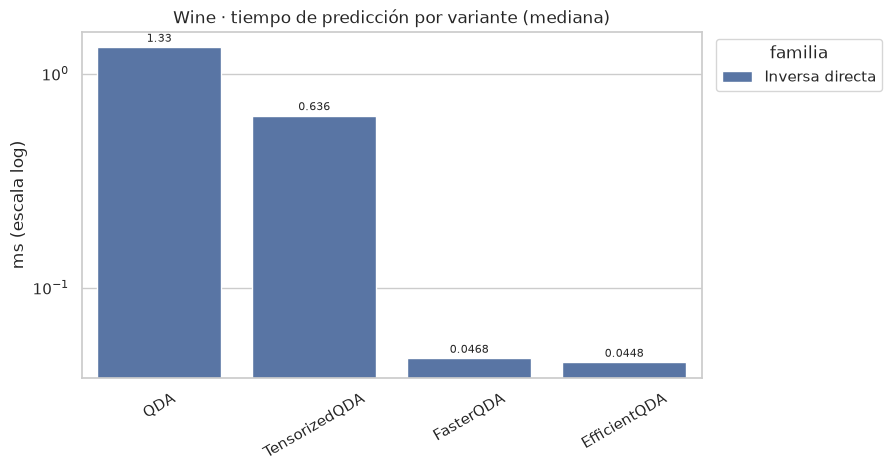

In [37]:
def grafico_barras_summary(summary: pd.DataFrame, columna: str, titulo: str, etiqueta_y: str, log: bool = False):
    """Barras por modelo coloreadas por familia (inversa directa vs. Cholesky)."""
    datos = summary[[columna]].reset_index()
    datos['familia'] = datos['model'].map(FAMILIA)
    ax = sns.barplot(data=datos, x='model', y=columna, hue='familia', dodge=False,
                     palette={'Inversa directa': '#4C72B0', 'Cholesky': '#DD8452'})
    ax.set_title(titulo); ax.set_xlabel(''); ax.set_ylabel(etiqueta_y)
    ax.tick_params(axis='x', rotation=30)
    sns.move_legend(ax, 'upper left', bbox_to_anchor=(1.01, 1))
    if log:
        ax.set_yscale('log')
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.3g', fontsize=8, padding=2)
    return ax


grafico_barras_summary(bench_wine.summary(), 'test_median_ms',
                       'Wine · tiempo de predicción por variante (mediana)', 'ms (escala log)', log=True);

**Interpretación (wine: $p=13$, $k=3$, $n_{test}=54$).** Los números exactos dependen de la máquina; el orden cualitativo no:
* **Exactitud idéntica** en las cuatro: son la misma función calculada de formas distintas.
* **`fit` ≈ igual** (heredan el de `QDA`) y **memoria de `fit` igual**.
* **`predict`**: `QDA` es el más lento (doble `for`, $n\cdot k$ llamadas a Python). `TensorizedQDA` elimina el
  factor $k$ y mejora poco; `FasterQDA` y `EfficientQDA` eliminan el `for` sobre $n$ y ganan más de un orden de magnitud.
* Con $n$ tan chico, `FasterQDA` y `EfficientQDA` casi empatan: el costo $n^2$ aún no domina. La sección 7.2
  muestra el barrido sobre $n$ donde la diferencia se hace evidente.

## 4. Cholesky (ejercicios 8 a 11)

### Ejercicio 8 · $A^{-1}$ en términos de $L$ y utilidad en QDA
Si $A = LL^\top$ con $L$ triangular inferior de diagonal positiva (existe y es única si $A$ es simétrica definida positiva):

$$A^{-1} = (LL^\top)^{-1} = (L^\top)^{-1}L^{-1} = (L^{-1})^\top L^{-1}$$

Reemplazando en la forma cuadrática de QDA, con $z = L_k^{-1}(x-\mu_k)$:

$$(x-\mu_k)^\top \Sigma_k^{-1} (x-\mu_k) = (x-\mu_k)^\top (L_k^{-1})^\top L_k^{-1} (x-\mu_k) = z^\top z = \lVert z \rVert^2$$

y para el determinante, como $\det L_k = \prod_i (L_k)_{ii}$ por ser triangular:

$$\ln|\Sigma_k| = \ln|L_k|^2 = 2\sum_{i=1}^{p} \ln (L_k)_{ii} \quad\Longrightarrow\quad -\tfrac12\ln|\Sigma_k| = -\sum_i \ln (L_k)_{ii}$$

**Consecuencias prácticas**
1. $z$ se obtiene resolviendo el sistema triangular $L_k z = x-\mu_k$ por *sustitución hacia adelante*, en $O(p^2)$, **sin invertir nada**.
2. El determinante es una suma de $p$ logaritmos: gratis.
3. **Estabilidad:** el número de condición de $\Sigma$ es el *cuadrado* del de $L$ ($\kappa(\Sigma)=\kappa(L)^2$). Trabajar con $L$ evita elevar al cuadrado los errores.
4. **Costo:** factorizar cuesta $\approx p^3/3$ flops frente a $\approx 2p^3$ de una inversión general (vía LU).

Lo comprobamos numéricamente, incluyendo la identidad $\ln|\Sigma| = 2\sum\ln L_{ii}$:

In [38]:
Sigma = np.cov(X_train[:, y_train.flatten() == 0], bias=True)
L = LA.cholesky(Sigma)                                         # triangular inferior

assert np.allclose(L @ L.T, Sigma)
assert np.allclose(LA.inv(Sigma), LA.inv(L).T @ LA.inv(L))     # A⁻¹ = (L⁻¹)ᵀ L⁻¹
logdet_cholesky = 2 * np.log(np.diag(L)).sum()
assert np.isclose(logdet_cholesky, LA.slogdet(Sigma)[1])
print(f'ln|Σ| por slogdet = {LA.slogdet(Sigma)[1]:.6f}  |  2·Σ ln L_ii = {logdet_cholesky:.6f}')
print(f'κ(Σ) = {LA.cond(Sigma):.3e}  vs  κ(L)² = {LA.cond(L) ** 2:.3e}  (iguales, κ(L) es la raíz)')

ln|Σ| por slogdet = -11.840016  |  2·Σ ln L_ii = -11.840016
κ(Σ) = 2.193e+07  vs  κ(L)² = 2.193e+07  (iguales, κ(L) es la raíz)


### Ejercicio 9 · `QDA_Chol1` vs `QDA`, paso a paso

| Etapa | `QDA` | `QDA_Chol1` |
|---|---|---|
| `fit` | guarda $\Sigma_k^{-1}$ (`LA.inv(Σ)`) | calcula $L_k$ por Cholesky y guarda $L_k^{-1}$ (`LA.inv(L)`) |
| determinante | `LA.det(inv_cov)` (genérico, $O(p^3)$) | `L_inv.diagonal().prod()`: producto de la diagonal |
| forma cuadrática | `x̃ᵀ Σ⁻¹ x̃` (dos productos matriciales) | `y = L⁻¹ x̃` (un producto) y `Σ y²` |

El puntaje es el mismo: $\ln|L_k^{-1}| = -\tfrac12 \ln|\Sigma_k|$ y $\lVert L_k^{-1}\tilde x\rVert^2 = \tilde x^\top \Sigma_k^{-1}\tilde x$.
Notar que `QDA_Chol1` sigue invirtiendo una matriz con `LA.inv` (ahora triangular, pero la rutina general no lo aprovecha).
Verificamos que los puntajes por clase coinciden hasta el redondeo:

In [39]:
chol1 = ajustar(QDA_Chol1, X_train, y_train)
x = X_test[:, [0]]
for c in range(k):
    puntaje_qda = float(np.squeeze(qda._predict_log_conditional(x, c)))
    puntaje_chol = float(np.squeeze(chol1._predict_log_conditional(x, c)))
    assert np.isclose(puntaje_qda, puntaje_chol), (c, puntaje_qda, puntaje_chol)
    print(f'clase {c}: QDA = {puntaje_qda:+.6f}   QDA_Chol1 = {puntaje_chol:+.6f}')
print('✔ Los puntajes coinciden; las predicciones también:',
      np.array_equal(chol1.predict(X_test), pred_qda))

clase 0: QDA = -92.999161   QDA_Chol1 = -92.999161
clase 1: QDA = -15.838756   QDA_Chol1 = -15.838756
clase 2: QDA = -14.371030   QDA_Chol1 = -14.371030
✔ Los puntajes coinciden; las predicciones también: True


### Ejercicio 10 · `QDA_Chol1` vs `QDA_Chol2` vs `QDA_Chol3`

| | Qué guarda en `fit` | Cómo obtiene $z=L^{-1}\tilde x$ | Costo extra |
|---|---|---|---|
| `Chol1` | $L^{-1}$ con `LA.inv` (inversión **general**, $\sim 2p^3$) | `L_inv @ x̃` | `fit` caro, `predict` barato |
| `Chol2` | $L$ (no invierte nunca) | `solve_triangular(L, x̃)` en **cada** llamada | `fit` barato, `predict` paga el solve y su *overhead* fijo $n\cdot k$ veces |
| `Chol3` | $L^{-1}$ con `dtrtri` (LAPACK **triangular**, $\sim p^3/3$) | `L_inv @ x̃` | `fit` barato y `predict` barato |

`Chol1` y `Chol3` calculan lo mismo (misma matriz $L^{-1}$) y predicen idéntico; solo difiere *cómo* se invierte.
`Chol2` desplaza el trabajo de `fit` a `predict`: conviene cuando se predicen pocas observaciones por cada entrenamiento.
Como cada `solve_triangular` tiene un costo fijo de llamada a SciPy, con $p$ chico y muchas observaciones pierde incluso
contra `QDA`; con $p$ grande gana a `QDA` porque evita recalcular el determinante en cada llamada (se mide en 7.2).

In [40]:
bench_chol = Benchmark(X_wine, label_encode(y_wine), n_runs=N_RUNS, warmup=WARMUP, mem_runs=MEM_RUNS,
                       test_sz=0.3, rng_seed=SEED)
for nombre in ['QDA', 'QDA_Chol1', 'QDA_Chol2', 'QDA_Chol3']:
    bench_chol.bench(MODELOS[nombre])
bench_chol.summary(baseline='QDA')[['train_median_ms', 'test_median_ms', 'mean_accuracy', 'train_speedup', 'test_speedup']]

Benching params:
Total runs: 240
Warmup runs: 20
Peak Memory usage runs: 20
Running time runs: 200
Train size rows (approx): 125
Test size rows (approx): 53
Test size fraction: 0.3


QDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

QDA_Chol1 (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA_Chol1 (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

QDA_Chol2 (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA_Chol2 (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

QDA_Chol3 (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA_Chol3 (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

,train_median_ms,test_median_ms,mean_accuracy,train_speedup,test_speedup
model,,,,,
QDA,0.184919,1.309480,0.982222,1.000000,1.000000
QDA_Chol1,0.224714,0.607213,0.982222,0.822908,2.156541
QDA_Chol2,0.192173,2.077999,0.982222,0.962250,0.630164
QDA_Chol3,0.186198,0.610704,0.982222,0.993131,2.144212


### Ejercicio 11 · Las 7 variantes
Se agregan las tres de Cholesky al benchmark de las cuatro anteriores:

In [41]:
bench_7 = Benchmark(X_wine, label_encode(y_wine), n_runs=N_RUNS, warmup=WARMUP, mem_runs=MEM_RUNS,
                    test_sz=0.3, rng_seed=SEED)
for nombre in list(MODELOS)[:7]:
    bench_7.bench(MODELOS[nombre])
resumen_7 = bench_7.summary(baseline='QDA')
resumen_7[['train_median_ms', 'test_median_ms', 'mean_accuracy', 'train_speedup', 'test_speedup', 'test_mem_median_mb']]

Benching params:
Total runs: 240
Warmup runs: 20
Peak Memory usage runs: 20
Running time runs: 200
Train size rows (approx): 125
Test size rows (approx): 53
Test size fraction: 0.3


QDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

TensorizedQDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

TensorizedQDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

...

QDA_Chol2 (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA_Chol2 (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

QDA_Chol3 (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA_Chol3 (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

,train_median_ms,test_median_ms,mean_accuracy,train_speedup,test_speedup,test_mem_median_mb
model,,,,,,
QDA,0.200972,1.345197,0.982222,1.000000,1.000000,0.008567
TensorizedQDA,0.199687,0.634550,0.982222,1.006438,2.119921,0.012711
FasterQDA,0.194010,0.048753,0.982222,1.035887,27.592076,0.109177
EfficientQDA,0.184570,0.045086,0.982222,1.088869,29.836230,0.060242
QDA_Chol1,0.224582,0.606243,0.982222,0.894873,2.218909,0.007149
QDA_Chol2,0.186974,2.037480,0.982222,1.074866,0.660226,0.007370
QDA_Chol3,0.182718,0.613810,0.982222,1.099905,2.191553,0.006943


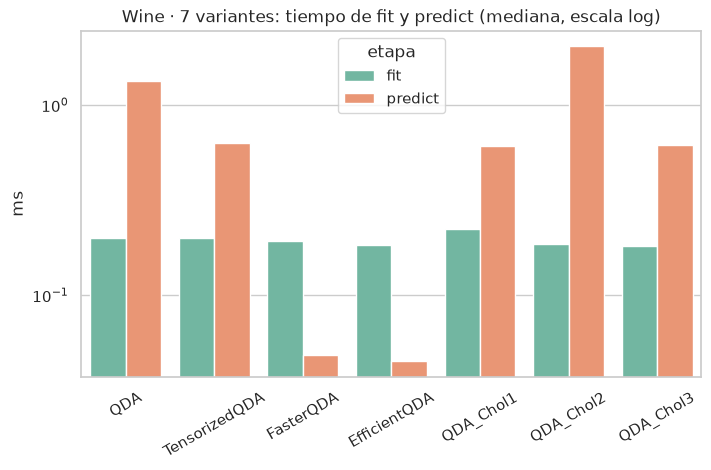

In [42]:
datos_tiempos = (resumen_7[['train_median_ms', 'test_median_ms']].rename(
    columns={'train_median_ms': 'fit', 'test_median_ms': 'predict'})
    .reset_index().melt(id_vars='model', var_name='etapa', value_name='ms'))
ax = sns.barplot(data=datos_tiempos, x='model', y='ms', hue='etapa', palette='Set2')
ax.set_yscale('log'); ax.set_title('Wine · 7 variantes: tiempo de fit y predict (mediana, escala log)')
ax.set_xlabel(''); ax.set_ylabel('ms'); ax.tick_params(axis='x', rotation=30);

**Interpretación (wine, $p=13$).**
* **Exactitud idéntica** en las 7, como corresponde.
* **`fit`:** con $p=13$ invertir o factorizar una matriz $13\times13$ cuesta microsegundos, así que las diferencias
  de entrenamiento son marginales y quedan dominadas por el overhead de Python y de `np.cov`. Habría que ver
  $p$ grande para que se note $p^3/3$ vs $2p^3$ (se barre en la sección 7).
* **`predict`:** `Chol1` y `Chol3` mejoran a `QDA` porque reemplazan `det` genérico + 2 matmuls por un producto de
  diagonal + 1 matmul; `Chol2` queda atrás por el overhead de `solve_triangular` en cada una de las $n\cdot k$ llamadas.
* **Ninguna** de las tres supera a `EfficientQDA`: la ganancia grande vino de **eliminar los `for`**, no de Cholesky.
* **Mejor equilibrio:** `QDA_Chol3` (`fit` barato + `predict` barato). **Peor en wine ($p=13$):** `QDA_Chol2`
  (esto depende de $p$; ver 7.2).

La conclusión natural es combinar ambos mundos: vectorizar *y* usar Cholesky (sección 5).

## 5. Cholesky tensorizado (ejercicios 12 y 13)

### Ejercicio 12 · `TensorizedChol`
Se hereda de `QDA_Chol3` (el mejor equilibrio según 11). Se apilan las $k$ matrices $L_k^{-1}$ en un tensor $(k,p,p)$ y las medias en
$(k,p,1)$, de modo que **una** llamada `tensor_L_invs @ (x - tensor_means)` calcula $z_k$ para todas las clases.
Sigue recorriendo las $n$ observaciones, igual que `TensorizedQDA`.

### Ejercicio 13 · `EfficientChol`
Con Cholesky **no hace falta el truco de la diagonal**. En QDA la forma cuadrática $\tilde x^\top\Sigma^{-1}\tilde x$ es
bilineal, por eso con $n$ observaciones aparecía la matriz $n\times n$. Con Cholesky la forma cuadrática es una
**norma al cuadrado**, que actúa columna a columna:

$$Z_k = L_k^{-1} X_c \in \mathbb{R}^{p\times n}, \qquad q_k(i) = \lVert Z_k[:, i] \rVert^2 = \sum_{j=1}^{p} Z_k[j,i]^2$$

Basta elevar al cuadrado y sumar sobre el eje de features: sin matriz $n\times n$, con memoria $O(kpn)$ y tiempo $O(kp^2n)$.

**Una mejora respecto del código original:** el término del determinante se calcula como
$\sum_i \ln (L^{-1})_{ii}$ (*suma de logaritmos*) y no como $\ln\prod_i (L^{-1})_{ii}$.
El producto de $p$ números puede desbordar o *underflowear* en doble precisión cuando $p$ es grande; la suma de logs, no.
La sección 6 muestra un caso donde esto cambia el resultado.

In [43]:
tchol = ajustar(TensorizedChol, X_train, y_train)
echol = ajustar(EfficientChol, X_train, y_train)

forma = pd.DataFrame({
    'objeto': ['tensor_L_invs', 'tensor_means', 'log_det_terms', 'X − tensor_means (predict de EfficientChol)',
               'Z = L⁻¹ X_c', 'términos cuadráticos Σ_j Z²'],
    'shape': [tchol.tensor_L_invs.shape, tchol.tensor_means.shape, tchol.log_det_terms.shape,
              (X_test - echol.tensor_means).shape, (echol.tensor_L_invs @ (X_test - echol.tensor_means)).shape,
              ((echol.tensor_L_invs @ (X_test - echol.tensor_means)) ** 2).sum(axis=1).shape],
    'significado': ['k matrices L_k⁻¹', 'k medias', 'k constantes −½ln|Σ_k|', '(k, p, n)', '(k, p, n)', '(k, n)']
}).set_index('objeto')
display(forma)

assert np.array_equal(tchol.predict(X_test), pred_qda)
assert np.array_equal(echol.predict(X_test), pred_qda)
assert echol.predict(X_test).shape == y_test.shape, 'la salida debe tener el shape de y'
print('✔ TensorizedChol y EfficientChol predicen igual que QDA, con el shape de y_test:', y_test.shape)

,shape,significado
objeto,,
tensor_L_invs,"(3, 13, 13)",k matrices L_k⁻¹
tensor_means,"(3, 13, 1)",k medias
log_det_terms,"(3,)",k constantes −½ln|Σ_k|
X − tensor_means (predict de EfficientChol),"(3, 13, 54)","(k, p, n)"
Z = L⁻¹ X_c,"(3, 13, 54)","(k, p, n)"
términos cuadráticos Σ_j Z²,"(3, 54)","(k, n)"


✔ TensorizedChol y EfficientChol predicen igual que QDA, con el shape de y_test: (1, 54)


## 6. Pruebas de corrección y robustez numérica

Que "den lo mismo en un ejemplo" no alcanza. Se prueban tres cosas:
1. **Equivalencia con un oráculo independiente** (`scipy.stats.multivariate_normal`) en 4 datasets × varias semillas.
2. **Invariantes de forma:** la salida siempre es `(1, n)`, enteros en $[0,k-1]$.
3. **Robustez numérica:** un caso con $p$ grande donde la implementación original *falla* y la nueva no.

Las funciones de verificación viven en `utils/verification.py` y las usan tanto este notebook como `tests/test_qda.py`
(`python -m unittest discover -s tests -t . -v`): una única definición de cada prueba.

### 6.1 Equivalencia contra un oráculo independiente
El oráculo calcula $\ln \pi_k + \ln\mathcal{N}(x;\mu_k,\Sigma_k)$ con `multivariate_normal.logpdf`, usando la misma
convención de covarianza (`bias=True`). Es código (`utils/verification.py`) que **no comparte** ninguna línea con las 9 variantes.

In [44]:
def verificar_equivalencia(nombres_datasets, semillas, nombres_modelos=None) -> pd.DataFrame:
    """Tabla (dataset, semilla) × modelo con True si coincide con el oráculo. Falla si hay algún False."""
    nombres_modelos = nombres_modelos or list(MODELOS)
    filas = []
    for dataset in nombres_datasets:
        for semilla in semillas:
            test_size = TEST_SZ_LETTERS if dataset == 'letters' else 0.3
            Xtr, Xte, ytr, yte = cargar(dataset, test_size=test_size, seed=semilla)
            esperado = prediccion_oraculo(Xtr, ytr, Xte)
            fila = {'dataset': dataset, 'semilla': semilla}
            for nombre in nombres_modelos:
                pred = ajustar(MODELOS[nombre], Xtr, ytr).predict(Xte)
                assert pred.shape == (1, Xte.shape[1]) and np.issubdtype(pred.dtype, np.integer), nombre
                fila[nombre] = bool(np.array_equal(pred, esperado))
            filas.append(fila)
    return pd.DataFrame(filas)


def barrido_un_hilo(*args, **kwargs) -> pd.DataFrame:
    """`barrido` con BLAS/LAPACK limitado a un hilo (ver docstring de `barrido`)."""
    with threadpool_limits(limits=1):
        return barrido(*args, **kwargs)


# 'letters' usa test chico por el costo de memoria de FasterQDA (ver sección 3)
DATASETS_EQUIVALENCIA = ['iris', 'wine', 'penguins'] + (['letters'] if USAR_LETTERS else [])
equivalencia = verificar_equivalencia(DATASETS_EQUIVALENCIA, semillas=[0, 1, 2, 3, 4])
display(equivalencia.set_index(['dataset', 'semilla']).replace({True: '✔', False: '✘'}))
assert equivalencia.drop(columns=['dataset', 'semilla']).all().all(), 'alguna variante difiere del oráculo'
print(f'✔ {equivalencia.shape[0]} corridas × {len(MODELOS)} modelos coinciden con el oráculo scipy')

QDA TensorizedQDA FasterQDA EfficientQDA QDA_Chol1 QDA_Chol2  \
dataset  semilla                                                                
iris     0         ✔             ✔         ✔            ✔         ✔         ✔   
         1         ✔             ✔         ✔            ✔         ✔         ✔   
         2         ✔             ✔         ✔            ✔         ✔         ✔   
         3         ✔             ✔         ✔            ✔         ✔         ✔   
         4         ✔             ✔         ✔            ✔         ✔         ✔   
wine     0         ✔             ✔         ✔            ✔         ✔         ✔   
         1         ✔             ✔         ✔            ✔         ✔         ✔   
         2         ✔             ✔         ✔            ✔         ✔         ✔   
         3         ✔             ✔         ✔            ✔         ✔         ✔   
         4         ✔             ✔         ✔            ✔         ✔         ✔   
penguins 0         ✔             ✔         ✔            ✔         ✔         ✔   
         1         ✔             ✔         ✔            ✔         ✔         ✔   
         2         ✔             ✔         ✔            ✔         ✔         ✔   
         3         ✔             ✔         ✔            ✔         ✔         ✔   
         4         ✔             ✔         ✔            ✔         ✔         ✔   
letters  0         ✔             ✔         ✔            ✔         ✔         ✔   
         1         ✔             ✔         ✔            ✔         ✔         ✔   
         2         ✔             ✔         ✔            ✔         ✔         ✔   
         3         ✔             ✔         ✔            ✔         ✔         ✔   
         4         ✔             ✔         ✔            ✔         ✔         ✔   

                 QDA_Chol3 TensorizedChol EfficientChol  
dataset  semilla                                         
iris     0               ✔              ✔             ✔  
         1               ✔              ✔             ✔  
         2               ✔              ✔             ✔  
         3               ✔              ✔             ✔  
         4               ✔              ✔             ✔  
wine     0               ✔              ✔             ✔  
         1               ✔              ✔             ✔  
         2               ✔              ✔             ✔  
         3               ✔              ✔             ✔  
         4               ✔              ✔             ✔  
penguins 0               ✔              ✔             ✔  
         1               ✔              ✔             ✔  
         2               ✔              ✔             ✔  
         3               ✔              ✔             ✔  
         4               ✔              ✔             ✔  
letters  0               ✔              ✔             ✔  
         1               ✔              ✔             ✔  
         2               ✔              ✔             ✔  
         3               ✔              ✔             ✔  
         4               ✔              ✔             ✔

✔ 20 corridas × 9 modelos coinciden con el oráculo scipy


### 6.2 Robustez numérica: cuando "más rápido" no alcanza
Con $p$ grande y varianzas chicas, $\det\Sigma$ queda fuera del rango de `float64` ($\approx 10^{\pm308}$).
Aquí $p=400$ y $\sigma^2 = 0{,}01$ ⇒ $\det\Sigma$ del orden de $10^{-800}$ a $10^{-900}$ (con la covarianza muestral resulta $\approx 10^{-870}$):
**underflow a 0**, y `log(0) = -inf`.
La *suma de logaritmos* de la diagonal de $L$ no tiene ese problema.

Términos de determinante para una clase (p=400):
  det(Σ)                      = 0.000e+00   ← underflow
  log(det(Σ))                 = -inf
  slogdet(Σ)                  = -2005.3082
  2·Σ ln L_ii (Cholesky)      = -2005.3082


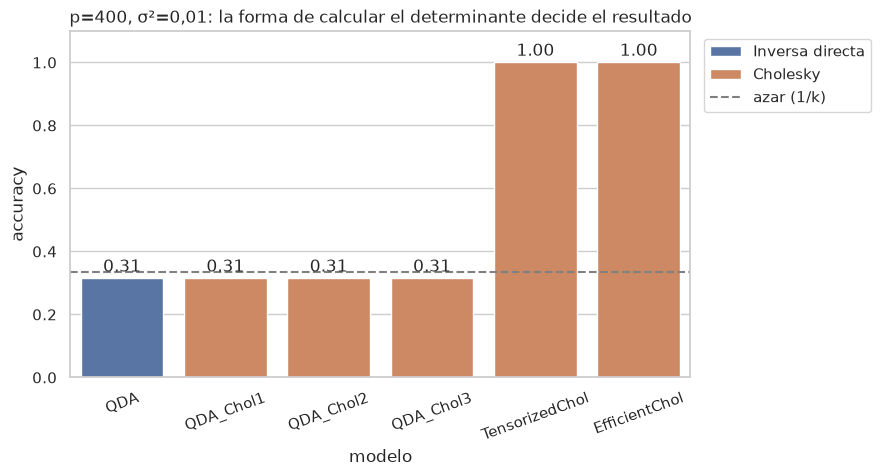

In [45]:
X_hd, y_hd = dataset_alta_dimension()
Xtr_hd, Xte_hd, ytr_hd, yte_hd = split_transpose(X_hd, y_hd, test_size=0.3, random_state=0)

Sigma_hd = np.cov(Xtr_hd[:, ytr_hd.flatten() == 0], bias=True)
print('Términos de determinante para una clase (p=400):')
print(f'  det(Σ)                      = {LA.det(Sigma_hd):.3e}   ← underflow')
with np.errstate(divide='ignore'):
    print(f'  log(det(Σ))                 = {np.log(LA.det(Sigma_hd))}')
print(f'  slogdet(Σ)                  = {LA.slogdet(Sigma_hd)[1]:.4f}')
print(f'  2·Σ ln L_ii (Cholesky)      = {2 * np.log(np.diag(LA.cholesky(Sigma_hd))).sum():.4f}')

filas = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for nombre in ['QDA', 'QDA_Chol1', 'QDA_Chol2', 'QDA_Chol3', 'TensorizedChol', 'EfficientChol']:
        pred = ajustar(MODELOS[nombre], Xtr_hd, ytr_hd).predict(Xte_hd)
        filas.append({'modelo': nombre, 'accuracy': (pred.flatten() == yte_hd.flatten()).mean(),
                      'familia': FAMILIA[nombre]})
robustez = pd.DataFrame(filas)
ax = sns.barplot(data=robustez, x='modelo', y='accuracy', hue='familia', dodge=False,
                 palette={'Inversa directa': '#4C72B0', 'Cholesky': '#DD8452'})
ax.axhline(1 / 3, ls='--', color='gray', label='azar (1/k)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_ylim(0, 1.1); ax.set_title('p=400, σ²=0,01: la forma de calcular el determinante decide el resultado')
ax.tick_params(axis='x', rotation=20)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f', padding=2)

> **Hallazgo.** `QDA`, `QDA_Chol1`, `QDA_Chol2` y `QDA_Chol3` caen a un resultado cercano al azar porque calculan el
> determinante como `log(prod(...))`/`log(det(...))`: el producto desborda (o underflowea) a $\pm\infty$ y el
> `argmax` deja de ser informativo. `TensorizedChol` y `EfficientChol` usan `sum(log(diag))` y clasifican perfecto.
> Es decir: **el motivo de fondo de usar Cholesky no es (solo) la velocidad: es poder calcular el determinante
> de forma estable.** Con $p$ chico (wine, $p=13$) este problema no se ve.

### 6.3 Pruebas de las propiedades matemáticas
Verificación de los resultados teóricos que se usaron arriba, sobre 50 entradas aleatorias (`utils/verification.py`):

In [46]:
for semilla in range(50):
    verificar_truco_diagonal(semilla)
    verificar_identidades_cholesky(semilla)
print('✔ 50 casos aleatorios: truco de la diagonal e identidades de Cholesky verificadas')

✔ 50 casos aleatorios: truco de la diagonal e identidades de Cholesky verificadas


## 7. Comparación final de las 9 variantes (ejercicio 14)

### 7.1 Benchmark del enunciado sobre `wine`

In [47]:
bench_9 = Benchmark(X_wine, label_encode(y_wine), n_runs=N_RUNS, warmup=WARMUP, mem_runs=MEM_RUNS,
                    test_sz=0.3, rng_seed=SEED)
for clase in MODELOS.values():
    bench_9.bench(clase)

resumen_9 = bench_9.summary(baseline='QDA')
resumen_9[['train_median_ms', 'test_median_ms', 'mean_accuracy', 'train_speedup', 'test_speedup',
           'train_mem_median_mb', 'test_mem_median_mb']]

Benching params:
Total runs: 240
Warmup runs: 20
Peak Memory usage runs: 20
Running time runs: 200
Train size rows (approx): 125
Test size rows (approx): 53
Test size fraction: 0.3


QDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

QDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

TensorizedQDA (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

TensorizedQDA (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

...

TensorizedChol (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

TensorizedChol (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

EfficientChol (MEM):   0%|          | 0/20 [00:00<?, ?it/s]

EfficientChol (TIME):   0%|          | 0/200 [00:00<?, ?it/s]

,train_median_ms,test_median_ms,mean_accuracy,train_speedup,test_speedup,train_mem_median_mb,test_mem_median_mb
model,,,,,,,
QDA,0.202633,1.357655,0.982222,1.000000,1.000000,0.018578,0.008567
TensorizedQDA,0.205449,0.641481,0.982222,0.986296,2.116438,0.018578,0.012711
FasterQDA,0.194380,0.047524,0.982222,1.042463,28.567780,0.018578,0.109177
EfficientQDA,0.184194,0.044788,0.982222,1.100112,30.313253,0.018578,0.060242
QDA_Chol1,0.230103,0.611849,0.982222,0.880623,2.218938,0.018578,0.007149
QDA_Chol2,0.189001,2.026823,0.982222,1.072132,0.669844,0.018372,0.007370
QDA_Chol3,0.168823,0.605600,0.982222,1.200272,2.241835,0.018372,0.006943
TensorizedChol,0.197021,0.304308,0.982222,1.028489,4.461443,0.018372,0.012093
EfficientChol,0.196065,0.027556,0.982222,1.033502,49.268056,0.018372,0.058838


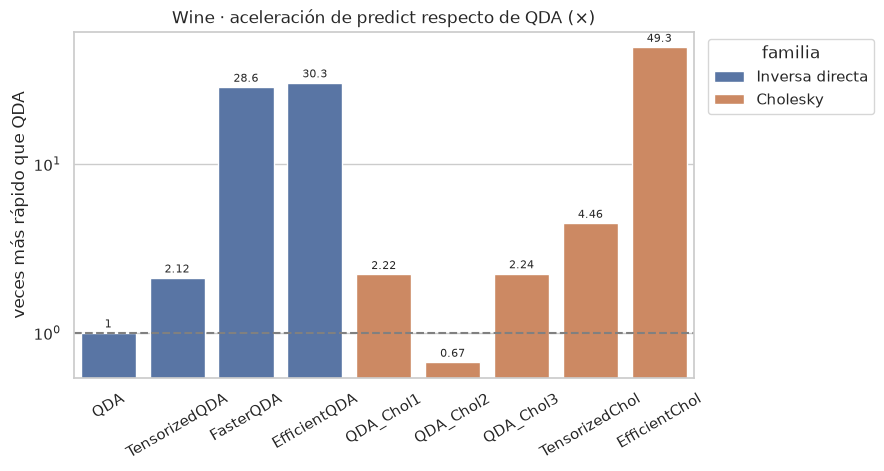

In [48]:
ax = grafico_barras_summary(resumen_9, 'test_speedup', 'Wine · aceleración de predict respecto de QDA (×)',
                            'veces más rápido que QDA', log=True)
ax.axhline(1, ls='--', color='gray');

### 7.2 ¿Cómo escala cada variante? Barridos sobre $n$, $p$ y $k$
El benchmark sobre wine ($n=54$, $p=13$, $k=3$) es un único punto. La teoría hace predicciones sobre *cómo crece*
el costo; para verificarlas se barre cada dimensión con datos sintéticos gaussianos (que cumplen el supuesto de QDA).

| Variante | Memoria de `predict` | Tiempo de `predict` |
|---|---|---|
| `QDA`, `TensorizedQDA` | $O(p^2)$ ($O(kp^2)$ la tensorizada) | $O(n\,k\,p^3)$: el `LA.det` de cada llamada cuesta $O(p^3)$ y se repite por (obs., clase); la tensorizada hace $n$ llamadas |
| `QDA_Chol1/2/3` | $O(p^2)$ | $O(n\,k\,p^2)$ con $n\cdot k$ llamadas de Python (el determinante ya está precomputado) |
| `TensorizedChol` | $O(kp^2)$ | $O(n\,k\,p^2)$ con $n$ llamadas |
| `FasterQDA` | $O(k\,n^2)$ | $O(k(p^3 + np^2 + n^2p))$ |
| `EfficientQDA` | $O(k\,p\,n)$ | $O(k(p^3 + np^2))$ |
| `EfficientChol` | $O(k\,p\,n)$ | $O(k\,p^2\,n)$ |

In [49]:
def dataset_sintetico(n_por_clase: int, p: int, k: int, seed: int = SEED):
    """k gaussianas con covarianzas (SPD) distintas. Devuelve X (n, p), y (n, 1)."""
    rng = np.random.default_rng(seed)
    bloques, etiquetas = [], []
    for c in range(k):
        M = rng.normal(size=(p, p))
        cov = M @ M.T / p + 0.5 * np.eye(p)
        bloques.append(rng.multivariate_normal(rng.normal(0, 1.5, p), cov, size=n_por_clase))
        etiquetas.append(np.full(n_por_clase, c))
    return np.vstack(bloques), np.concatenate(etiquetas).reshape(-1, 1)


def mediana_ms(funcion, repeticiones: int = 5) -> float:
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        funcion()
        tiempos.append((time.perf_counter() - inicio) * 1e3)
    return float(np.median(tiempos))


def pico_memoria_mb(funcion) -> float:
    tracemalloc.start()
    funcion()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 2**20


def barrido(parametro: str, valores, base: dict, modelos: list[str], medir_fit: bool = False) -> pd.DataFrame:
    """Para cada valor del parámetro (n_test, p o k) mide tiempo y memoria de predict (y opcionalmente de fit).

    Se fija 1 hilo de BLAS: con muchos núcleos, las rutinas LAPACK triangulares (cholesky, dtrtri, inv) sufren
    contención de hilos y los tiempos de `fit` salen erráticos (entre 10 y 40× más lentos que con 1 hilo,
    medido en una máquina de 16 núcleos). Con 1 hilo se mide el costo *algorítmico*, que es lo que predice la teoría.
    """
    filas = []
    for valor in valores:
        cfg = {**base, parametro: valor}
        X, y = dataset_sintetico(cfg['n_train_por_clase'], cfg['p'], cfg['k'])
        Xtr, ytr = X.T, y.T
        n_test_por_clase = -(-cfg['n_test'] // cfg['k'])                    # techo: alcanza para cortar n_test columnas
        Xte = dataset_sintetico(n_test_por_clase, cfg['p'], cfg['k'], seed=SEED + 1)[0].T[:, :cfg['n_test']]
        for nombre in modelos:
            clase = MODELOS[nombre]
            modelo = clase()
            fila = {parametro: valor, 'modelo': nombre, 'familia': FAMILIA[nombre]}
            fila['fit_ms'] = mediana_ms(lambda: clase().fit(Xtr, ytr), repeticiones=5) if medir_fit else np.nan
            modelo.fit(Xtr, ytr)
            fila['predict_ms'] = mediana_ms(lambda: modelo.predict(Xte), repeticiones=5)
            fila['predict_mem_mb'] = pico_memoria_mb(lambda: modelo.predict(Xte))
            filas.append(fila)
    return pd.DataFrame(filas)


def grafico_barrido(df: pd.DataFrame, x: str, y: str, titulo: str, etiqueta_y: str, logx=True, logy=True):
    ax = sns.lineplot(data=df, x=x, y=y, hue='modelo', style='modelo', markers=True, dashes=False, linewidth=2)
    if logx: ax.set_xscale('log')
    if logy: ax.set_yscale('log')
    ax.set_title(titulo); ax.set_ylabel(etiqueta_y)
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8)
    return ax


TODOS = list(MODELOS)
BASE = {'n_train_por_clase': 300, 'p': 10, 'k': 3, 'n_test': 300}

**Barrido sobre $n$ (observaciones a predecir)** — $p=10$, $k=3$ fijos. Se espera: `FasterQDA` con memoria $\propto n^2$
(pendiente 2 en escala log-log) y el resto con memoria $\propto n$ o constante.

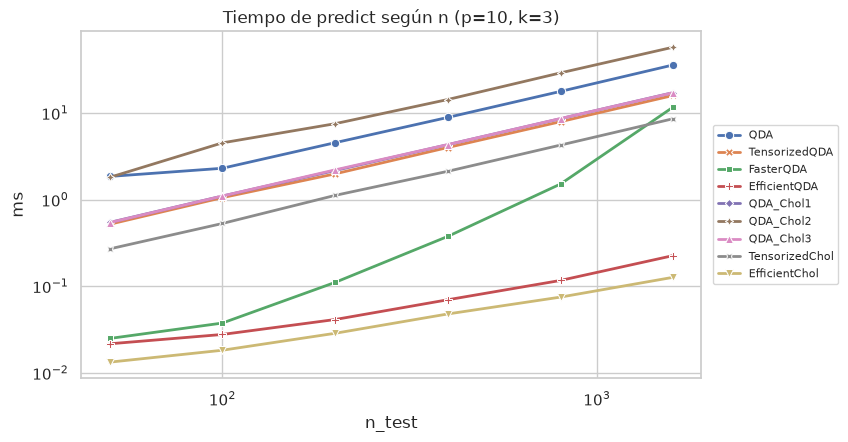

In [50]:
barrido_n = barrido_un_hilo('n_test', [50, 100, 200, 400, 800, 1600], BASE, TODOS)
grafico_barrido(barrido_n, 'n_test', 'predict_ms', 'Tiempo de predict según n (p=10, k=3)', 'ms');

In [51]:
def tabla_barrido(df: pd.DataFrame, parametro: str, metrica: str) -> pd.DataFrame:
    """Pivote modelo × valor del parámetro, para leer los números detrás del gráfico."""
    return df.pivot(index='modelo', columns=parametro, values=metrica).loc[
        [m for m in MODELOS if m in set(df['modelo'])]].round(3)


display(tabla_barrido(barrido_n, 'n_test', 'predict_ms').style.set_caption('predict_ms según n_test'))

n_test,50,100,200,400,800,1600
modelo,,,,,,
QDA,1.852000,2.302000,4.543000,8.900000,17.773000,35.940000
TensorizedQDA,0.519000,1.054000,1.984000,3.998000,7.947000,15.967000
FasterQDA,0.025000,0.038000,0.111000,0.376000,1.514000,11.736000
EfficientQDA,0.022000,0.028000,0.041000,0.070000,0.117000,0.226000
QDA_Chol1,0.545000,1.100000,2.168000,4.316000,8.614000,17.226000
QDA_Chol2,1.806000,4.524000,7.530000,14.324000,29.095000,57.634000
QDA_Chol3,0.543000,1.100000,2.205000,4.320000,8.637000,17.181000
TensorizedChol,0.270000,0.530000,1.119000,2.124000,4.266000,8.604000
EfficientChol,0.013000,0.018000,0.029000,0.048000,0.075000,0.127000


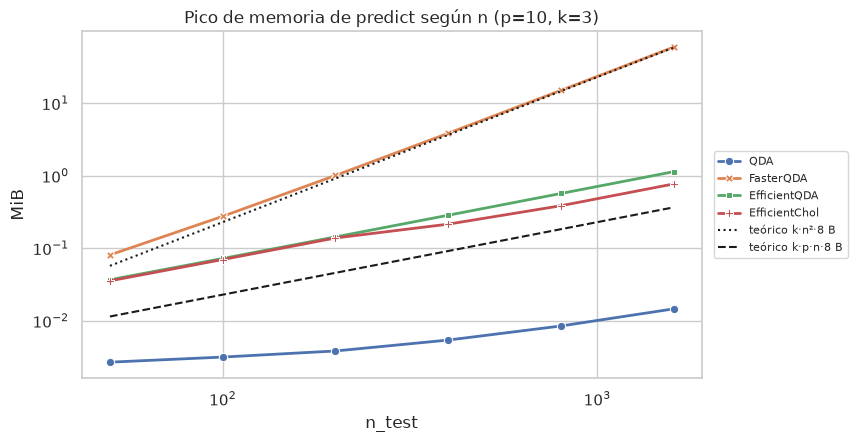

In [52]:
# memoria medida vs. la fórmula teórica de los dos intermedios dominantes
ax = grafico_barrido(barrido_n[barrido_n.modelo.isin(['FasterQDA', 'EfficientQDA', 'EfficientChol', 'QDA'])],
                     'n_test', 'predict_mem_mb', 'Pico de memoria de predict según n (p=10, k=3)', 'MiB')
n_ref = np.array(sorted(barrido_n['n_test'].unique()))
ax.plot(n_ref, BASE['k'] * n_ref ** 2 * 8 / 2**20, 'k:', label='teórico k·n²·8 B')
ax.plot(n_ref, BASE['k'] * BASE['p'] * n_ref * 8 / 2**20, 'k--', label='teórico k·p·n·8 B')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8);

In [53]:
# Exponente empírico: pendiente de log(memoria) vs log(n). Teoría: 2 para FasterQDA, 1 para EfficientQDA/EfficientChol.
pendientes = {}
for nombre in ['FasterQDA', 'EfficientQDA', 'EfficientChol']:
    sub_df = barrido_n[barrido_n.modelo == nombre]
    pendientes[nombre] = np.polyfit(np.log(sub_df['n_test']), np.log(sub_df['predict_mem_mb']), 1)[0]
pd.Series(pendientes, name='exponente empírico de n (memoria)').round(2).to_frame()

,exponente empírico de n (memoria)
FasterQDA,1.91
EfficientQDA,0.99
EfficientChol,0.86


**Lectura del barrido sobre $n$** (corrida de referencia; las magnitudes absolutas dependen de la máquina)
* **Memoria:** `FasterQDA` sigue la curva teórica $k\,n^2\cdot 8$ B (exponente empírico $\approx 2$). `EfficientQDA` y `EfficientChol`
  crecen $\approx$ linealmente (exponente $\approx 1$) con una constante $\approx 3$ veces la teórica $k\,p\,n\cdot 8$ B, porque
  `predict` mantiene simultáneamente unos tres arreglos $(k,p,n)$ (en `EfficientChol`: el centrado, $Z$ y $Z^2$). Misma pendiente, otra constante.
  `QDA` casi no usa memoria: procesa una observación por vez (paga con tiempo, no con memoria).
* **Tiempo:** `QDA` y `TensorizedQDA` crecen **linealmente** en $n$ (un `for` de Python por observación; `TensorizedQDA` es
  ≈ 2× más rápido porque el `for` de clases desaparece). `FasterQDA` es muy rápida para $n$ chico pero
  **crece de forma super-lineal** (de $n=50$ a $n=1600$ el tiempo se multiplica por ≈ 350–450 según la corrida, con $n$ multiplicado por 32) y para
  $n=1600$ ya es ≈ 45–50× más lenta que `EfficientQDA`. `EfficientChol` es la más rápida en todo el rango.

**Barrido sobre $p$ (features)** — $n_{test}=300$, $k=3$. Es el único eje donde Cholesky debería mostrar su ventaja
de entrenamiento ($p^3/3$ vs $2p^3$) y donde aparece el costo $p^2$ por observación en `predict`.

p,4,16,64,128,256,512
modelo,,,,,,
QDA,0.302000,0.324000,0.852000,2.798000,10.591000,50.384000
TensorizedQDA,0.256000,0.342000,0.862000,2.528000,9.986000,51.012000
EfficientQDA,0.255000,0.332000,0.857000,2.478000,10.006000,54.310000
QDA_Chol1,0.272000,0.386000,0.919000,2.746000,11.789000,55.415000
QDA_Chol2,0.245000,0.351000,1.061000,1.847000,5.931000,23.154000
QDA_Chol3,0.250000,0.332000,0.877000,2.108000,7.452000,32.747000
EfficientChol,0.277000,0.359000,0.807000,2.125000,7.594000,38.498000


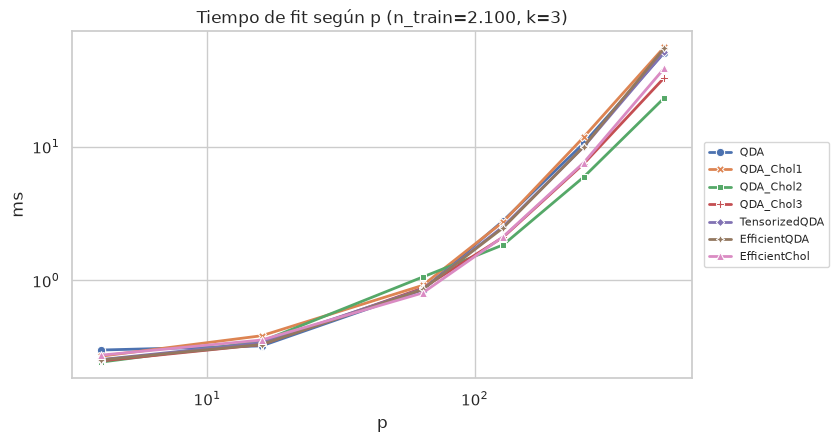

In [54]:
base_p = {**BASE, 'n_train_por_clase': 700}
barrido_p = barrido_un_hilo('p', [4, 16, 64, 128, 256, 512], base_p, ['QDA', 'QDA_Chol1', 'QDA_Chol2', 'QDA_Chol3',
                                                                 'TensorizedQDA', 'EfficientQDA', 'EfficientChol'],
                    medir_fit=True)
grafico_barrido(barrido_p, 'p', 'fit_ms', 'Tiempo de fit según p (n_train=2.100, k=3)', 'ms')
display(tabla_barrido(barrido_p, 'p', 'fit_ms').style.set_caption('fit_ms según p'));

p,4,16,64,128,256,512
modelo,,,,,,
QDA,6.480000,8.094000,22.298000,76.507000,397.920000,3518.648000
TensorizedQDA,2.614000,3.754000,17.998000,70.866000,380.432000,3162.240000
EfficientQDA,0.047000,0.068000,0.353000,1.031000,4.067000,22.548000
QDA_Chol1,3.281000,3.494000,3.752000,4.646000,14.191000,47.050000
QDA_Chol2,11.049000,12.000000,16.601000,15.936000,29.889000,94.055000
QDA_Chol3,3.243000,3.299000,3.902000,4.665000,13.585000,47.481000
EfficientChol,0.023000,0.045000,0.235000,0.744000,2.611000,11.362000


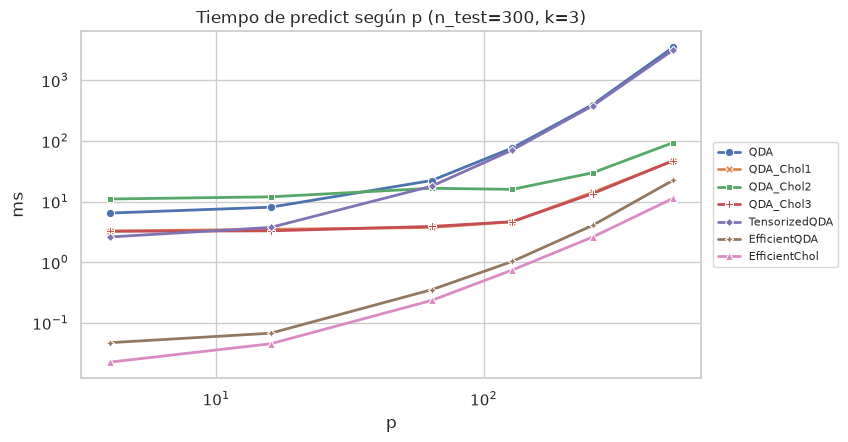

In [55]:
grafico_barrido(barrido_p, 'p', 'predict_ms', 'Tiempo de predict según p (n_test=300, k=3)', 'ms')
display(tabla_barrido(barrido_p, 'p', 'predict_ms').style.set_caption('predict_ms según p'));

**Lectura del barrido sobre $p$**
* **`fit` (1 hilo):** `QDA`, `TensorizedQDA` y `EfficientQDA` coinciden (comparten `_fit_params`: es la verificación de que la
  medición es consistente). Para $p=512$: `Chol2` ≈ 2× más rápido que `QDA`, `Chol3` ≈ 1,6×, y `Chol1` queda algo **más lenta** que `QDA` (≈ 0,85×:
  hace Cholesky **y** además una inversión general, así que no gana). El orden `Chol2 < Chol3 < QDA ≈ Chol1` es el que predice el conteo
  de operaciones ($p^3/3$ solo factorizar; $p^3/3 + p^3/3$ factorizar e invertir triangular; $p^3/3 + 2p^3$ factorizar e invertir
  general; $2p^3$ invertir $\Sigma$). La ganancia total es menor que el cociente teórico porque **`np.cov` cuesta $O(n_k p^2)$ y es
  común a todas las variantes** (ley de Amdahl).
* **`predict`:** aquí está la diferencia grande. Para $p=512$, `QDA` y `TensorizedQDA` tardan del orden de **segundos** y
  `Chol1`/`Chol3` unas **decenas de ms** (≈ 50–65× menos). La causa es que `QDA` recalcula `LA.det(inv_cov)` —$O(p^3)$— en **cada**
  (observación, clase), mientras que con Cholesky el determinante es una suma de $p$ logaritmos que se calcula una sola vez.
  `Chol2` queda en el medio (≈ 30× más rápida que `QDA` y ≈ 2× más lenta que `Chol1/3`): también evita el determinante, pero paga un
  `solve_triangular` por llamada. `EfficientQDA` también evita ese costo (calcula el determinante una vez por llamada a `predict`);
  `EfficientChol` es ≈ 2× más rápida que ella.

> **Nota metodológica sobre hilos.** Con BLAS multihilo en una máquina de 16 núcleos, el `fit` de las variantes con Cholesky
> resultó ser entre 10 y 40× *más lento* que con un solo hilo (contención de hilos en rutinas LAPACK de matrices
> medianas), invirtiendo el orden teórico. Por eso los barridos fijan 1 hilo (`threadpool_limits`): miden el costo
> algorítmico. En una máquina real conviene medir *ambos* regímenes antes de elegir implementación.

**Barrido sobre $k$ (clases)** — $p=8$, $n_{test}=300$. Las variantes con `for` sobre clases deberían crecer
linealmente con $k$; las tensorizadas, mucho menos.

k,2,4,8,16,32
modelo,,,,,
QDA,4.932000,8.669000,16.289000,31.257000,60.472000
TensorizedQDA,2.688000,3.053000,3.581000,4.661000,6.916000
FasterQDA,0.127000,0.269000,0.586000,1.132000,2.722000
EfficientQDA,0.036000,0.060000,0.109000,0.203000,0.416000
QDA_Chol1,2.417000,4.023000,7.746000,14.605000,26.753000
QDA_Chol2,7.447000,14.010000,27.662000,54.788000,105.842000
QDA_Chol3,2.406000,4.050000,7.544000,13.345000,26.343000
TensorizedChol,1.554000,1.634000,1.754000,1.837000,2.160000
EfficientChol,0.026000,0.041000,0.079000,0.121000,0.238000


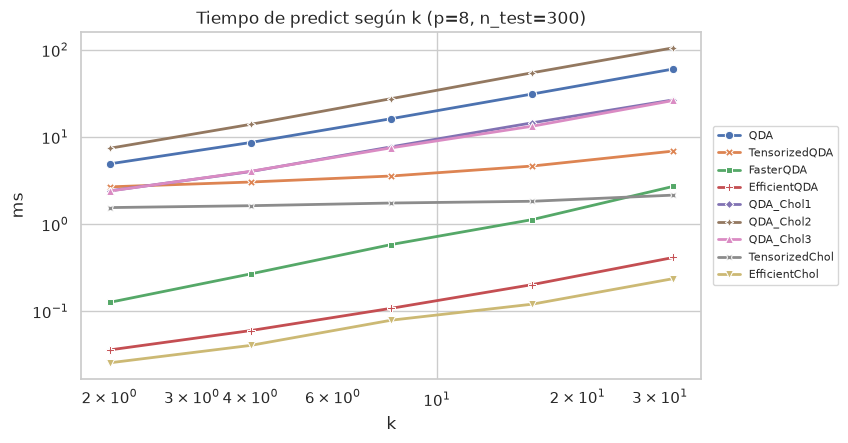

In [56]:
base_k = {**BASE, 'p': 8, 'n_train_por_clase': 200}
barrido_k = barrido_un_hilo('k', [2, 4, 8, 16, 32], base_k, TODOS)
grafico_barrido(barrido_k, 'k', 'predict_ms', 'Tiempo de predict según k (p=8, n_test=300)', 'ms')
display(tabla_barrido(barrido_k, 'k', 'predict_ms').style.set_caption('predict_ms según k'));

**Lectura del barrido sobre $k$.** `QDA` y `Chol1/2/3` crecen linealmente con $k$ (≈ 11–14× al pasar de $k=2$ a $k=32$, con
$k$ multiplicado por 16): el `for` sobre clases está en Python. `TensorizedQDA` y `TensorizedChol` crecen mucho menos
(≈ 2,5× y ≈ 1,4×): el `for` de clases ya es un `matmul` batcheado y lo que domina es el `for` de Python sobre las $n$ observaciones,
que no depende de $k$. `FasterQDA`, `EfficientQDA` y `EfficientChol` sí crecen con $k$ (≈ 9–18×, el trabajo útil es $\propto k$),
pero parten de un nivel mucho más bajo (con $k=32$: ≈ 30× menos tiempo que `QDA` para `FasterQDA`, ≈ 150–170× para `EfficientQDA` y
≈ 250–280× para `EfficientChol`): la mejora está en la constante, no en la pendiente.

### 7.3 Dataset real grande: `letters`
$p=16$, $k=26$, 20.000 observaciones. Se usa un test del 5 % (1.000 obs.) para que `FasterQDA` quepa en memoria
(≈ 0,2 GiB; con el 30 % serían ≈ 7 GiB). Pocas repeticiones porque `QDA` tarda ~segundos por predicción.

In [57]:
if USAR_LETTERS:
    X_let, y_let = get_letters_dataset()
    bench_letters = Benchmark(X_let, label_encode(y_let), n_runs=8, warmup=2, mem_runs=3,
                              test_sz=TEST_SZ_LETTERS, rng_seed=SEED)
    for clase in MODELOS.values():
        bench_letters.bench(clase)
    resumen_letters = bench_letters.summary(baseline='QDA')
    display(resumen_letters[['train_median_ms', 'test_median_ms', 'mean_accuracy', 'test_speedup',
                             'train_mem_median_mb', 'test_mem_median_mb']])

Benching params:
Total runs: 13
Warmup runs: 2
Peak Memory usage runs: 3
Running time runs: 8
Train size rows (approx): 19000
Test size rows (approx): 1000
Test size fraction: 0.05


QDA (MEM):   0%|          | 0/3 [00:00<?, ?it/s]

QDA (TIME):   0%|          | 0/8 [00:00<?, ?it/s]

TensorizedQDA (MEM):   0%|          | 0/3 [00:00<?, ?it/s]

TensorizedQDA (TIME):   0%|          | 0/8 [00:00<?, ?it/s]

...

TensorizedChol (MEM):   0%|          | 0/3 [00:00<?, ?it/s]

TensorizedChol (TIME):   0%|          | 0/8 [00:00<?, ?it/s]

EfficientChol (MEM):   0%|          | 0/3 [00:00<?, ?it/s]

EfficientChol (TIME):   0%|          | 0/8 [00:00<?, ?it/s]

,train_median_ms,test_median_ms,mean_accuracy,test_speedup,train_mem_median_mb,test_mem_median_mb
model,,,,,,
QDA,5.571290,211.604431,0.88525,1.000000,0.297722,0.076162
TensorizedQDA,5.635143,45.441631,0.88525,4.656621,0.297722,0.131454
FasterQDA,8.370994,48.712023,0.88525,4.343988,0.297722,204.828423
EfficientQDA,5.439095,2.037666,0.88525,103.846474,0.297722,9.836861
QDA_Chol1,5.947114,86.917596,0.88525,2.434541,0.297722,0.071739
QDA_Chol2,5.323678,308.552202,0.88525,0.685798,0.297516,0.072180
QDA_Chol3,5.510026,85.301277,0.88525,2.480671,0.297516,0.071533
TensorizedChol,5.493335,7.741509,0.88525,27.333746,0.297516,0.131622
EfficientChol,5.458422,1.507395,0.88525,140.377556,0.297516,6.662956


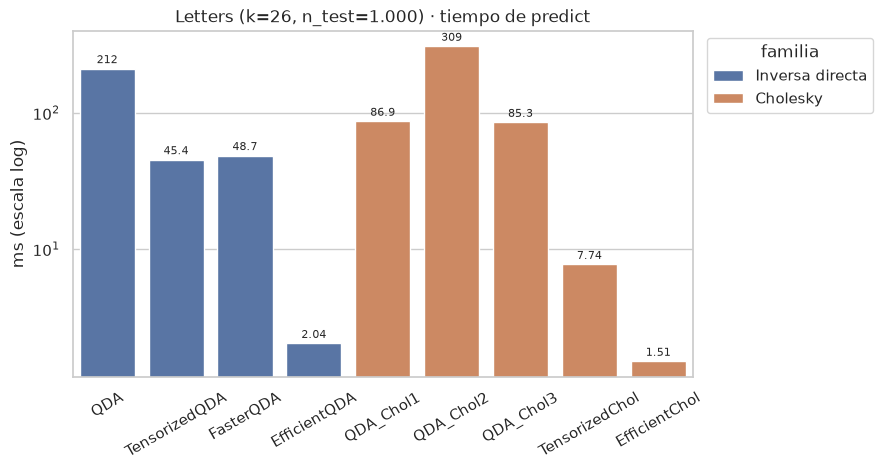

In [58]:
if USAR_LETTERS:
    ax = grafico_barras_summary(resumen_letters, 'test_median_ms',
                                'Letters (k=26, n_test=1.000) · tiempo de predict', 'ms (escala log)', log=True)

**Lectura de `letters`** ($k=26$, $p=16$, $n_{test}=1.000$). Se repite lo visto en los barridos con un dataset real:
la exactitud es idéntica en las 9 variantes; `EfficientQDA` y `EfficientChol` son del orden de 100× y 150–170× más rápidas que `QDA`;
`FasterQDA` es sólo entre 3× y 6× más rápida (varía entre corridas; son pocas repeticiones) y es la única que aloca cientos de MiB (≈ 200 MiB, como indica $k\,n^2\cdot 8$ B),
mientras que `EfficientQDA` usa ≈ 10 MiB y `EfficientChol` ≈ 7 MiB. `QDA_Chol2` vuelve a ser más lenta que `QDA`.

>Con el test del 30 % ($n=6.000$) `FasterQDA` pide ≈ 7 GiB y termina siendo **más lenta que `QDA`** (en una corrida con ese tamaño: ≈ 1.190 ms contra ≈ 910 ms de mediana en `predict`): otra consecuencia de pagar $n^2$.

## 8. Conclusiones

*(Las magnitudes absolutas dependen de la máquina; los cocientes y las pendientes son los que se sostienen.)*

| # | Conclusión | Evidencia en este notebook |
|---|---|---|
| 1 | **Eliminar los `for` rinde más que cambiar de álgebra.** | `TensorizedQDA` (quita $k$) ≈ 2×; quitar $n$: `FasterQDA` y `EfficientQDA` ≈ 30× en wine, pero en letters (n grande) `EfficientQDA` ≈ 100× y `FasterQDA` sólo 3–6× |
| 2 | **Vectorizar sin cuidar la memoria es una trampa.** `FasterQDA` materializa $k\,n^2$ elementos | exponente empírico ≈ 1,9; 7 GiB proyectados en letters con 30 % de test; ≈ 45–50× más lenta que `EfficientQDA` en $n=1600$ |
| 3 | **La identidad $\operatorname{diag}(AB)=\sum A\odot B^\top$ elimina esa matriz** | `EfficientQDA`: exponente de memoria ≈ 1,0 y mismas predicciones |
| 4 | **Con Cholesky la forma cuadrática es una norma: el truco de la diagonal deja de hacer falta.** | `EfficientChol` es la más rápida en todos los barridos y usa menos memoria que `EfficientQDA` |
| 5 | **Cholesky ayuda sobre todo en `predict` y en estabilidad, no tanto en `fit` con $p$ chico.** | wine: `fit` ≈ igual; $p=512$: `predict` ≈ 50–65× menos (determinante precomputado); `fit` 1,6–2,2× por `Chol3`/`Chol2` |
| 6 | **`log(prod(diag))` o `log(det)` fallan con $p$ grande; `sum(log(diag))` no.** | $p=400$: `QDA` y `Chol1/2/3` ≈ azar, `TensorizedChol`/`EfficientChol` ≈ 100 % |
| 7 | **`QDA_Chol2` mueve el costo a `predict`; `QDA_Chol3` es el mejor equilibrio entre las tres originales.** | $p\le 16$ (wine, letters): `Chol2` ≈ 0,65× de la velocidad de `QDA` en `predict`; con $p=512$ es ≈ 30× más rápida que `QDA` pero ≈ 2× más lenta que `Chol1/3`; la más rápida en `fit` |
| 8 | **Todas son equivalentes.** | 20 corridas × 9 modelos coinciden con un oráculo independiente (`scipy.stats`); 50 casos aleatorios de las identidades; `tests/test_qda.py` repite estas pruebas sin el notebook |

**Variante recomendada: `EfficientChol`.** Sin `for`, sin matriz $n\times n$, sin inversa general, con determinante estable.

### Limitaciones y trabajo futuro
* `QDA` no regulariza: con $p \ge n_k$ la covarianza de una clase es singular y `cholesky`/`inv` fallan. Una
  regularización $\Sigma + \lambda I$ (como `reg_param` en scikit-learn) lo resolvería.
* Se midió en CPU con 1 hilo de BLAS (y con el multihilo se observó contención): el balance entre variantes puede cambiar con otra
  configuración de hardware o con GPU.
* Para $\kappa(L)$ muy alto, multiplicar por $L^{-1}$ explícita pierde precisión frente a resolver el sistema triangular;
  un `solve_triangular` batcheado sería más robusto aunque no existe como primitiva única en NumPy/SciPy.
* La exactitud de QDA sobre `letters` ($\approx 0{,}885$) no es el objetivo del TP, que es computacional.

In [1]:
# Versiones utilizadas
import sys, numpy, scipy
print(f"Python {sys.version.split()[0]}")
print(f"NumPy  {numpy.__version__}")
print(f"SciPy  {scipy.__version__}")

Python 3.12.14
NumPy  2.3.1
SciPy  1.16.0
